2

Task 2: Simple Linear Regression using OLS (Auto MPG Dataset)
● Exam Task:
1. Load the Auto MPG dataset, extract Horsepower as the predictor and MPG as
the target variable, and drop/impute any null rows.
2. Add the intercept/bias term and calculate the Ordinary Least Squares (OLS)
closed-form weights analytically using the normal equation ( ).𝑤
^ = (𝑋𝑇𝑋)−1𝑋𝑇𝑦
3. Predict the target values and compute the Mean Squared Error (MSE) and 𝑅2
score
4. Plot the fitted regression line over the data scatter plot


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Load the Auto MPG dataset, extract Horsepower and MPG, and drop nulls
url = "http://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
column_names = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
                'acceleration', 'model year', 'origin', 'car name']

df = pd.read_csv(url, names=column_names, na_values='?', comment='\t', sep=' ', skipinitialspace=True)

# Clean missing values
df_clean = df[['horsepower', 'mpg']].dropna()

X = df_clean['horsepower'].values
y = df_clean['mpg'].values

print(f"Successfully reloaded dataset. Number of valid samples: {len(df_clean)}")

Successfully reloaded dataset. Number of valid samples: 392


In [ ]:
# 2. Add the intercept/bias term and calculate OLS closed-form weights analytically
X_design = np.vstack([np.ones(len(X)), X]).T # Add column of ones for intercept

# Calculate analytical weights: w = (X^T * X)^-1 * X^T * y
weights = np.linalg.inv(X_design.T @ X_design) @ X_design.T @ y
intercept, slope = weights[0], weights[1]

print("Calculated OLS weights analytically:")
print(f"Intercept (w0): {intercept:.4f}")
print(f"Slope (w1): {slope:.4f}")

Calculated OLS weights analytically:
Intercept (w0): 39.9359
Slope (w1): -0.1578


In [ ]:
# 3. Predict target values and compute Mean Squared Error (MSE) and R2 score
y_pred = X_design @ weights

# Mean Squared Error
mse = np.mean((y - y_pred) ** 2)

# R-squared Score
ss_tot = np.sum((y - np.mean(y)) ** 2)
ss_res = np.sum((y - y_pred) ** 2)
r2 = 1 - (ss_res / ss_tot)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-squared (R2) Score: {r2:.4f}")

Mean Squared Error (MSE): 23.9437
R-squared (R2) Score: 0.6059


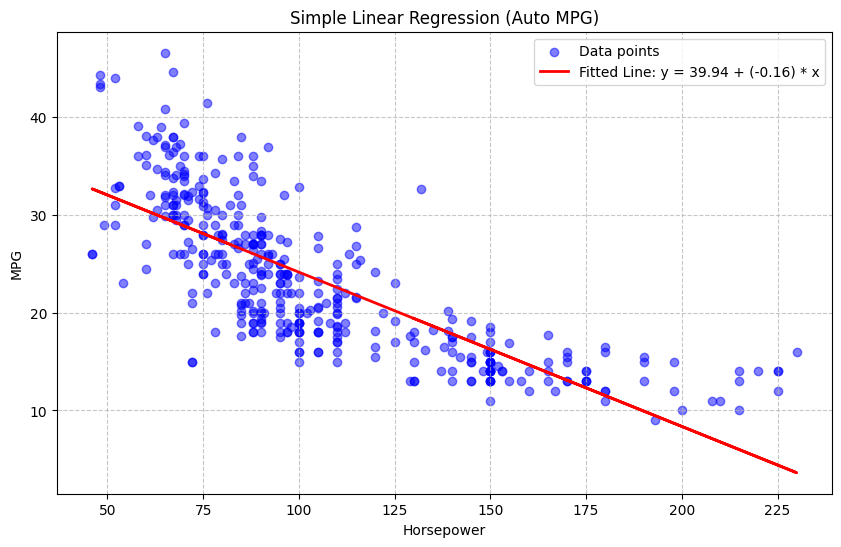

In [ ]:
# 4. Plot the fitted regression line over the data scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='blue', alpha=0.5, label='Data points')
plt.plot(X, y_pred, color='red', linewidth=2, label=f'Fitted Line: y = {intercept:.2f} + ({slope:.2f}) * x')
plt.xlabel('Horsepower')
plt.ylabel('MPG')
plt.title('Simple Linear Regression (Auto MPG)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [ ]:
# 3. Predict the target values and compute MSE and R2 score
y_pred = X_design @ weights

# Mean Squared Error
mse = np.mean((y - y_pred) ** 2)

# R2 Score
ss_tot = np.sum((y - np.mean(y)) ** 2)
ss_res = np.sum((y - y_pred) ** 2)
r2 = 1 - (ss_res / ss_tot)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R-squared (R2) Score: {r2:.4f}")

Mean Squared Error (MSE): 23.9437
R-squared (R2) Score: 0.6059


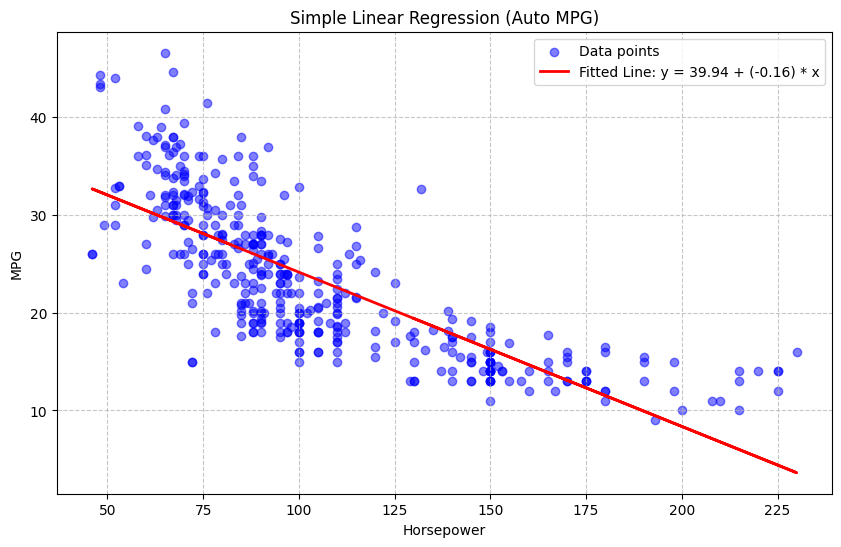

In [ ]:
# 4. Plot the fitted regression line over the data scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='blue', alpha=0.5, label='Data points')
plt.plot(X, y_pred, color='red', linewidth=2, label=f'Fitted Line: y = {intercept:.2f} + ({slope:.2f}) * x')
plt.xlabel('Horsepower')
plt.ylabel('MPG')
plt.title('Simple Linear Regression (Auto MPG)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()